In [1]:
import numpy as np
import pandas as pd
from mhcgnomes import parse

# 1 Read total data

In [2]:
#DATA_PATH = '/home/denklewer/Data/' #ubuntu
EXPERIMENT_NAME = 'length_dependent_hmm'
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
DATA_PATH = f'{DATA_PATH_BASE}/'

IEDB_DATA_PATH = DATA_PATH + 'Binding data/IEDB/mhc_ligand_full_single_file/mhc_ligand_full.csv'
NetMHCPan_41_DATA_PATH = DATA_PATH + 'Binding data/NetMHCpan-4.1/NetMHCpan_train/'


In [3]:
iedb_df = pd.read_csv(IEDB_DATA_PATH, sep=',', header=[0,1])


C:\Users\denkl\AppData\Local\Temp\ipykernel_9156\281494706.py:1: DtypeWarning: Columns (5,14,23,24,25,26,29,30,31,32,33,34,35,36,37,38,41,42,43,44,45,46,47,48,49,50,53,54,55,56,57,58,59,60,61,62,63,64,65,68,69,70,71,72,73,74,75,76,77,78,81,84,89,90,91,92,93,94,97,99) have mixed types. Specify dtype option on import or set low_memory=False.
  iedb_df = pd.read_csv(IEDB_DATA_PATH, sep=',', header=[0,1])


In [4]:
len(iedb_df)

3235984

In [5]:
def tuple_to_last_elem(column):
    return column[-1]

def filter_iedb_dataset(iedb_df, include_qualitative=True, include_mass_spec=True):
    QUALITATIVE_TO_AFFINITY_AND_INEQUALITY = {
    "Negative": (5000.0, ">"),
    "Positive": (500.0, "<"),  # used for mass-spec hits
    "Positive-High": (100.0, "<"),
    "Positive-Intermediate": (1000.0, "<"),
    "Positive-Low": (5000.0, "<"),
    }
    QUALITATIVE_TO_AFFINITY = dict(
        (key, value[0]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())
    QUALITATIVE_TO_INEQUALITY = dict(
        (key, value[1]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())
    
    
    
    print("Loaded iedb data: %s" % str(iedb_df.shape))
    filtered_df = iedb_df.copy()
    filtered_df = filtered_df[filtered_df[('Epitope', 'Object Type')] == "Linear peptide"]

    print("Linear peptides only, remaining: %d" % len(filtered_df))
    
    ## Clear bad data
    print("Subselecting to valid peptides (dropping peptides with PTMs). Starting with: %d" % len(filtered_df))
    filtered_df[('Epitope', 'Description')] = filtered_df[('Epitope', 'Description')].str.strip()
    filtered_df = filtered_df.loc[
        iedb_df[('Epitope', 'Description')].str.match("^[ACDEFGHIKLMNPQRSTVWY]+$")
    ]
    filtered_df = filtered_df.reset_index(drop=True)
    print("Now: %d" % len(filtered_df))
    
    
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("\+")]
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("X")]
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("B")]
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("Z")]
    filtered_df = filtered_df[[
    ('Epitope', 'Object Type'),
    ('Epitope', 'Description'),
    ('Epitope', 'Parent Species'),
    ('Assay', 'Units'),
    ('Assay', 'Qualitative Measure'),
    ('Assay', 'Quantitative measurement'),
     ('Assay', 'Measurement Inequality'),
    ('MHC', 'Allele Name'),
    ('MHC', 'Allele IRI'),
    ('MHC', 'MHC allele class'),
    ('Assay', 'Assay Group'),
    ('Assay', 'Method/Technique'),
    ('Epitope', 'Parent Protein IRI'),
    ('Epitope', 'Starting Position'),
    ('Epitope', 'Ending Position')
             ]]
    print("Subselecting assay groups as in Sarkizova. Starting with: %d" % len(filtered_df))

    assay_type1 = (filtered_df[('Assay', 'Assay Group')] == 'half maximal effective concentration (EC50)') & \
                                              (filtered_df[('Assay', 'Method/Technique')] == 'purified MHC/direct/fluorescence')
    filtered_df = filtered_df[~assay_type1]
    assay_type2 = (filtered_df[('Assay', 'Assay Group')] =='dissociation constant KD') & \
                                                  (filtered_df[('Assay', 'Method/Technique')] == 'purified MHC/direct/radioactivity')
    filtered_df = filtered_df[~assay_type2]
    assay_type3 = (filtered_df[('Assay', 'Assay Group')] == 'half maximal effective concentration (EC50)') & \
                                                  (filtered_df[('Assay', 'Method/Technique')] == 'cellular MHC/direct/fluorescence')
    filtered_df = filtered_df[~assay_type3]
    filtered_df.columns = filtered_df.columns.map(tuple_to_last_elem)
    filtered_df = filtered_df.reset_index(drop=True)
    print("Now: %d" % len(filtered_df))


    quantitative = filtered_df.loc[filtered_df["Units"] == "nM"].copy()
    quantitative["measurement_type"] = "quantitative"
    quantitative = quantitative.rename(columns={"Measurement Inequality":"measurement_inequality"})
    quantitative['measurement_inequality'] = quantitative['measurement_inequality'].fillna("=").map(lambda s: {">=": ">", "<=": "<"}.get(s, s))
    print("Quantitative measurements: %d" % len(quantitative))
    # Ilya: remove quantitative measurement with no measurement values
    print("Dropping quantitative measurements with no measurement value")
    quantitative.dropna(subset = ["Quantitative measurement"], inplace=True)
    print("Quantitative measurements: %d" % len(quantitative))
    
    qualitative = filtered_df.loc[filtered_df["Units"] != "nM"].copy()
    qualitative["measurement_type"] = "qualitative"
    print("Qualitative measurements: %d" % len(qualitative))
    if not include_mass_spec:
        qualitative = qualitative.loc[
            (~qualitative["Method/Technique"].str.contains("mass spec"))
        ].copy()

    qualitative["Quantitative measurement"] = (
        qualitative["Qualitative Measure"].map(QUALITATIVE_TO_AFFINITY))
    qualitative = qualitative.drop(columns=['Measurement Inequality'])
    qualitative["measurement_inequality"] = (qualitative["Qualitative Measure"].map(QUALITATIVE_TO_INEQUALITY))
    print("Qualitative measurements (possibly after dropping MS): %d" % (
        len(qualitative)))
    
    filtered_df = pd.concat(
        (
            ([quantitative]) +
            ([qualitative] if include_qualitative else [])),
        ignore_index=True)
    print("Now: %d" % len(filtered_df))
    
    ## Mark binders
    binder_list = ['Positive', 'Positive-High', 'Positive-Intermediate', 'Positive-Low']
    non_binder_list = ['Negative']
    filtered_df.loc[filtered_df['Quantitative measurement'] <= 500, 'binder'] = 1
    filtered_df.loc[filtered_df['Quantitative measurement'] > 500, 'binder'] = 0
    #
    # filtered_df.loc[filtered_df['Qualitative Measure'].isin(binder_list),'binder'] = 1
    # filtered_df.loc[filtered_df['Qualitative Measure'].isin(non_binder_list),'binder'] = 0
    
    filtered_df.binder = filtered_df.binder.astype(int)
    filtered_df = filtered_df.drop(columns=[
     # 'Qualitative Measure',
     'Units',
     'Object Type',
     'Allele IRI'
     ])
    
    filtered_df = filtered_df.rename(columns={"Allele Name":"allele", 
                                              "Description":"peptide",
                                              "Quantitative measurement":"measurement_value",
                                              'Qualitative Measure': "qualitative_measurement",
                                              "Parent Protein IRI":"protein_id",
                                              "Starting Position":"peptide_start",
                                              "Ending Position": "peptide_end"})
    filtered_df['length'] = filtered_df['peptide'].str.len()
    
    #filtered_df['allele'] = filtered_df['original_allele'].map(parse).to_string()
    
    print("Take unique (peptide, allele, length, 'measurement_value', 'measurement_inequality','qualitative_measurement' 'measurement_type', binder). Starting with: %d" % len(filtered_df))

    filtered_df = filtered_df.drop_duplicates([
    'peptide',
    'allele',
    'length',
    'measurement_value',
    'measurement_inequality',
    'measurement_type',
    'qualitative_measurement',
    'binder',
    'protein_id',
    'peptide_start',
    'peptide_end']).reset_index(drop=True)
    print("Now: %d" % len(filtered_df))

    
    print("Allele_distribution")
    print(filtered_df['allele'].value_counts()[:30])
    


    assert 'peptide' in filtered_df.columns
    assert 'allele' in filtered_df.columns
    assert 'length' in filtered_df.columns
    assert 'binder' in filtered_df.columns
    return filtered_df

In [6]:
ALLELES = [
    'H2-IAb',
    'HLA-A*02:01',
    'HLA-B*27:05',
    'HLA-B*07:02',
    'HLA-A*03:01',
    'HLA-A*01:01',
    'HLA-A*24:02',
    'HLA-A*11:01',
    'HLA-DRB1*01:01',
    'HLA-DRB1*04:01',
    'HLA-DRB1*03:01',
    'HLA-DRB1*04:01',
    'HLA-DRB1*15:01',
    'HLA-DRB3*01:01',
    'HLA-DRB5*01:01',
    'HLA-DPA1*01:03/DPB1*04:01', 
    'HLA-DPA1*02:02/DPB1*05:01' ]

In [7]:
iedb_df = filter_iedb_dataset(iedb_df)


Loaded iedb data: (3235984, 100)
Linear peptides only, remaining: 3235229
Subselecting to valid peptides (dropping peptides with PTMs). Starting with: 3235229
Now: 3104634
Subselecting assay groups as in Sarkizova. Starting with: 3104634
Now: 3103070
Quantitative measurements: 235469
Dropping quantitative measurements with no measurement value
Quantitative measurements: 235321
Qualitative measurements: 2867601
Qualitative measurements (possibly after dropping MS): 2867601
Now: 3102922
Take unique (peptide, allele, length, 'measurement_value', 'measurement_inequality','qualitative_measurement' 'measurement_type', binder). Starting with: 3102922
Now: 1690159
Allele_distribution
HLA class I                  334186
HLA class II                 143459
HLA-B*27:05                   94782
HLA-A*02:01                   68664
HLA-B*07:02                   32392
HLA-DR                        31141
HLA-B*57:01                   26965
HLA-A*01:01                   23274
HLA-B*15:02                

In [8]:
len(iedb_df)

1690159

In [9]:
target_df = iedb_df[iedb_df.allele.isin(ALLELES)]

In [10]:
target_df.allele.value_counts(dropna=False)

HLA-B*27:05                  94782
HLA-A*02:01                  68664
HLA-B*07:02                  32392
HLA-A*01:01                  23274
HLA-A*24:02                  21306
HLA-DRB1*01:01               20323
HLA-A*03:01                  16799
HLA-A*11:01                  16619
HLA-DPA1*01:03/DPB1*04:01    14808
HLA-DPA1*02:02/DPB1*05:01    11729
HLA-DRB1*04:01                9836
HLA-DRB1*15:01                9437
HLA-DRB5*01:01                6986
H2-IAb                        6857
HLA-DRB1*03:01                5407
HLA-DRB3*01:01                3753
Name: allele, dtype: int64

In [11]:
target_df.binder.value_counts(dropna=False)

1    284417
0     78555
Name: binder, dtype: int64

In [12]:
qual = target_df[target_df.measurement_type == 'qualitative']

In [13]:
qual.qualitative_measurement.value_counts(dropna=False)

Positive                 257321
Negative                  34541
Positive-High              2573
Positive-Low               1961
Positive-Intermediate      1598
Name: qualitative_measurement, dtype: int64

In [14]:
qual.binder.value_counts(sort=False, dropna=False)

0     38100
1    259894
Name: binder, dtype: int64

In [15]:
qual[qual.binder == 1]

,peptide,Parent Species,qualitative_measurement,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_id,peptide_start,peptide_end,measurement_type,binder,length
230465,ATLGFGAYM,Hepacivirus C,Positive,500.0,<,HLA-A*02:01,I,qualitative binding,purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/P27958,1260.0,1268.0,qualitative,1,9
230467,LTNQNINIDQEFNLMKHGFH,NaN,Positive,500.0,<,HLA-DRB1*03:01,II,qualitative binding,purified MHC/competitive/fluorescence,NaN,NaN,NaN,qualitative,1,20
230468,LLDVTAAV,Homo sapiens,Positive,500.0,<,HLA-A*02:01,I,ligand presentation,cellular MHC/mass spectrometry,NaN,NaN,NaN,qualitative,1,8
230469,YTNQNINISMERNLMKHGFH,NaN,Positive,500.0,<,HLA-DRB1*04:01,II,qualitative binding,purified MHC/competitive/fluorescence,NaN,NaN,NaN,qualitative,1,20
230470,LLSAEPVPA,Homo sapiens,Positive,500.0,<,HLA-A*02:01,I,ligand presentation,cellular MHC/mass spectrometry,http://www.uniprot.org/uniprot/P40259,20.0,28.0,qualitative,1,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1668445,SLYDLDIEA,NaN,Positive,500.0,<,HLA-A*02:01,I,qualitative binding,cellular MHC/direct/fluorescence,NaN,NaN,NaN,qualitative,1,9
1668447,TMSLYDLDIEA,NaN,Positive,500.0,<,HLA-A*02:01,I,qualitative binding,cellular MHC/direct/fluorescence,NaN,NaN,NaN,qualitative,1,11
1668450,SLYDLDIEAS,NaN,Positive,500.0,<,HLA-A*02:01,I,qualitative binding,cellular MHC/direct/fluorescence,NaN,NaN,NaN,qualitative,1,10
1682882,VVGAVGVGK,NaN,Positive,500.0,<,HLA-A*03:01,I,ligand presentation,cellular MHC/mass spectrometry,NaN,NaN,NaN,qualitative,1,9


In [16]:
quan = target_df[target_df.measurement_type == 'quantitative']

In [17]:
(quan.measurement_value <= 500).value_counts(sort=False)

True     24523
False    40455
Name: measurement_value, dtype: int64

In [18]:
quan.binder.value_counts(dropna=False, sort=False)

1    24523
0    40455
Name: binder, dtype: int64

In [19]:
quan[quan.qualitative_measurement == 'Positive-Low']

,peptide,Parent Species,qualitative_measurement,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_id,peptide_start,peptide_end,measurement_type,binder,length
6,KVIQPRVEK,Severe acute respiratory syndrome-related coro...,Positive-Low,595.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P0C6X7,282.0,290.0,quantitative,0,9
12,AVDPAKAYK,Severe acute respiratory syndrome-related coro...,Positive-Low,1674.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P0C6X7,4250.0,4258.0,quantitative,0,9
14,YIFFASFYY,Severe acute respiratory syndrome-related coro...,Positive-Low,1176.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P0C6X7,2361.0,2369.0,quantitative,0,9
16,KCYGVSATK,Severe acute respiratory syndrome-related coro...,Positive-Low,2069.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59594,365.0,373.0,quantitative,0,9
17,KCYGVSATK,Severe acute respiratory syndrome-related coro...,Positive-Low,8376.0,=,HLA-A*11:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59594,365.0,373.0,quantitative,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230425,KTWGQYWQV,Homo sapiens,Positive-Low,1000.0,<,HLA-A*02:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P40967,154.0,162.0,quantitative,0,9
230426,AMLGTHTMEV,Homo sapiens,Positive-Low,1000.0,<,HLA-A*02:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P40967,177.0,186.0,quantitative,0,10
230427,ITDQVPFSV,Homo sapiens,Positive-Low,1000.0,<,HLA-A*02:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P40967,209.0,217.0,quantitative,0,9
230430,SYLEQASRI,Homo sapiens,Positive-Low,1000.0,<,HLA-A*24:02,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P14679,466.0,474.0,quantitative,0,9


In [20]:
target_df[target_df.measurement_type == 'quantitative'].binder.value_counts()

0    40455
1    24523
Name: binder, dtype: int64

In [21]:
import seaborn as sns

In [22]:
df = target_df[target_df.measurement_type == 'quantitative']

<AxesSubplot: xlabel='measurement_value', ylabel='qualitative_measurement'>

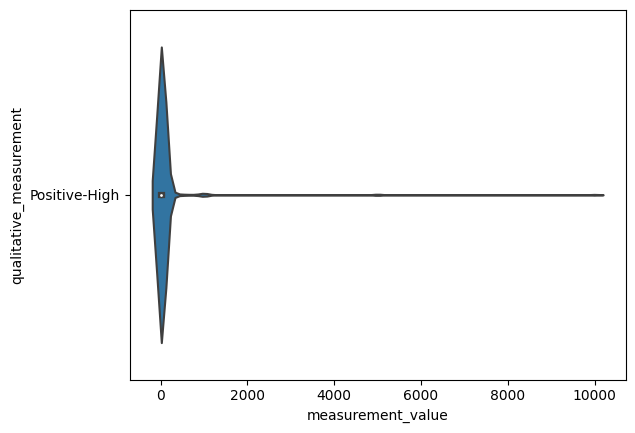

In [23]:
sns.violinplot(data=df[df.qualitative_measurement == 'Positive-High'], x='measurement_value', y='qualitative_measurement')

<AxesSubplot: xlabel='measurement_value', ylabel='Count'>

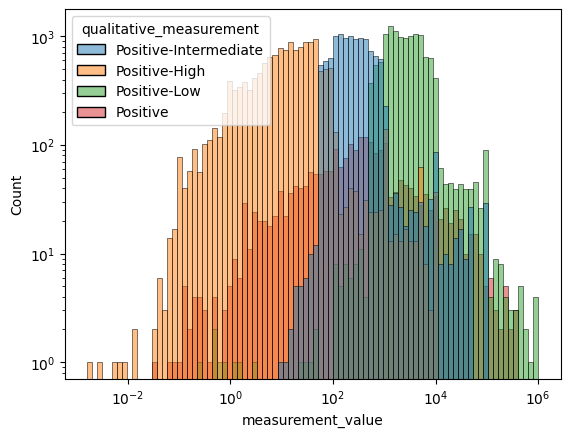

In [24]:
sns.histplot(data=df[df.qualitative_measurement != 'Negative'], x='measurement_value', hue='qualitative_measurement', log_scale=(True, True))

In [25]:
df[df.qualitative_measurement == 'Positive-Low']['measurement_value'].describe()

count      12218.000000
mean        5850.647027
std        26396.053074
min            0.250000
25%         1262.500000
50%         2371.750000
75%         4680.000000
max      1000000.000000
Name: measurement_value, dtype: float64

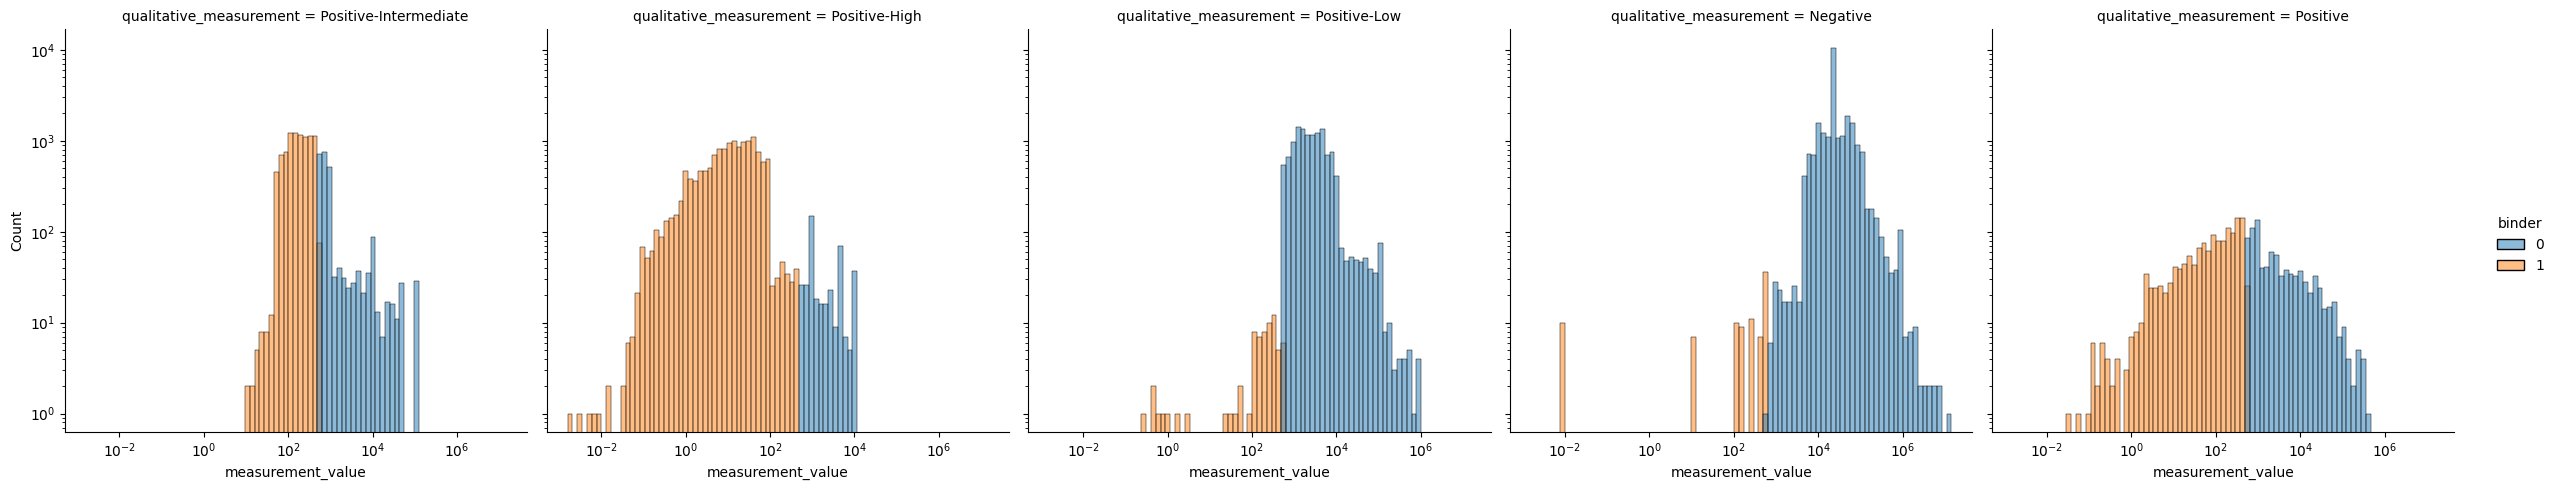

In [26]:
sns.displot(data=df, x='measurement_value', hue='binder', col='qualitative_measurement',  log_scale=(True, True))

In [27]:
assert target_df.qualitative_measurement.notna().all()

In [28]:
target_df[target_df.measurement_type == 'quantitative']

,peptide,Parent Species,qualitative_measurement,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_id,peptide_start,peptide_end,measurement_type,binder,length
0,EVMPVSMAK,Severe acute respiratory syndrome-related coro...,Positive-Intermediate,473.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59594,707.0,715.0,quantitative,1,9
1,EVMPVSMAK,Severe acute respiratory syndrome-related coro...,Positive-High,19.0,=,HLA-A*11:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59594,707.0,715.0,quantitative,1,9
2,KTFPPTEPK,Severe acute respiratory syndrome-related coro...,Positive-Intermediate,186.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59595,362.0,370.0,quantitative,1,9
3,KTFPPTEPK,Severe acute respiratory syndrome-related coro...,Positive-Intermediate,70.0,=,HLA-A*11:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59595,362.0,370.0,quantitative,1,9
4,ATFSVPMEK,Severe acute respiratory syndrome-related coro...,Positive-Intermediate,265.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P0C6X7,2577.0,2585.0,quantitative,1,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230433,QLPDFVNQL,NaN,Positive,100.0,<,HLA-A*02:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,NaN,NaN,NaN,quantitative,1,9
230434,HLIDSNTLQV,NaN,Positive-High,10.0,<,HLA-A*02:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,NaN,NaN,NaN,quantitative,1,10
230443,RSLEYLPLRF,Homo sapiens,Negative,10000.0,>,HLA-A*24:02,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/K7ESP4,198.0,207.0,quantitative,0,10
230448,HLIDPNTLQV,Homo sapiens,Positive-High,10.0,<,HLA-A*02:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/C9JA08,282.0,291.0,quantitative,1,10


In [29]:
target_df.measurement_type.value_counts()

qualitative     297994
quantitative     64978
Name: measurement_type, dtype: int64

In [30]:
target_df

,peptide,Parent Species,qualitative_measurement,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_id,peptide_start,peptide_end,measurement_type,binder,length
0,EVMPVSMAK,Severe acute respiratory syndrome-related coro...,Positive-Intermediate,473.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59594,707.0,715.0,quantitative,1,9
1,EVMPVSMAK,Severe acute respiratory syndrome-related coro...,Positive-High,19.0,=,HLA-A*11:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59594,707.0,715.0,quantitative,1,9
2,KTFPPTEPK,Severe acute respiratory syndrome-related coro...,Positive-Intermediate,186.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59595,362.0,370.0,quantitative,1,9
3,KTFPPTEPK,Severe acute respiratory syndrome-related coro...,Positive-Intermediate,70.0,=,HLA-A*11:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59595,362.0,370.0,quantitative,1,9
4,ATFSVPMEK,Severe acute respiratory syndrome-related coro...,Positive-Intermediate,265.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P0C6X7,2577.0,2585.0,quantitative,1,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1668457,YTQSEMEFL,NaN,Negative,5000.0,>,HLA-A*02:01,I,qualitative binding,cellular MHC/direct/fluorescence,NaN,NaN,NaN,qualitative,0,9
1682882,VVGAVGVGK,NaN,Positive,500.0,<,HLA-A*03:01,I,ligand presentation,cellular MHC/mass spectrometry,NaN,NaN,NaN,qualitative,1,9
1682883,VVVGAVGVGK,NaN,Positive,500.0,<,HLA-A*03:01,I,ligand presentation,cellular MHC/mass spectrometry,NaN,NaN,NaN,qualitative,1,10
1682884,VVGAVGVGK,NaN,Negative,5000.0,>,HLA-A*02:01,I,ligand presentation,cellular MHC/mass spectrometry,NaN,NaN,NaN,qualitative,0,9


In [31]:
binder_list = ['Positive', 'Positive-High', 'Positive-Intermediate', 'Positive-Low']
df = target_df[(target_df['qualitative_measurement'].isin(binder_list)) & (target_df['measurement_value'] > 500)]


In [32]:
df

,peptide,Parent Species,qualitative_measurement,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_id,peptide_start,peptide_end,measurement_type,binder,length
6,KVIQPRVEK,Severe acute respiratory syndrome-related coro...,Positive-Low,595.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P0C6X7,282.0,290.0,quantitative,0,9
12,AVDPAKAYK,Severe acute respiratory syndrome-related coro...,Positive-Low,1674.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P0C6X7,4250.0,4258.0,quantitative,0,9
14,YIFFASFYY,Severe acute respiratory syndrome-related coro...,Positive-Low,1176.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P0C6X7,2361.0,2369.0,quantitative,0,9
16,KCYGVSATK,Severe acute respiratory syndrome-related coro...,Positive-Low,2069.0,=,HLA-A*03:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59594,365.0,373.0,quantitative,0,9
17,KCYGVSATK,Severe acute respiratory syndrome-related coro...,Positive-Low,8376.0,=,HLA-A*11:01,I,dissociation constant KD (~EC50),purified MHC/direct/fluorescence,http://www.uniprot.org/uniprot/P59594,365.0,373.0,quantitative,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1640810,LLDDEAGPL,Hepatitis B virus,Positive-Low,5000.0,<,HLA-A*02:01,I,qualitative binding,cellular MHC/direct/fluorescence,http://www.uniprot.org/uniprot/Q69028,13.0,21.0,qualitative,0,9
1640811,YVIGSWGTL,Hepatitis B virus,Positive-Low,5000.0,<,HLA-A*02:01,I,qualitative binding,cellular MHC/direct/fluorescence,http://www.uniprot.org/uniprot/Q69028,598.0,606.0,qualitative,0,9
1640812,YMDDVVLGA,Hepatitis B virus,Positive-Low,5000.0,<,HLA-A*02:01,I,qualitative binding,cellular MHC/direct/fluorescence,http://www.uniprot.org/uniprot/Q69028,549.0,557.0,qualitative,0,9
1640813,WILRGTSFV,Hepatitis B virus,Positive-Low,5000.0,<,HLA-A*02:01,I,qualitative binding,cellular MHC/direct/fluorescence,http://www.uniprot.org/uniprot/Q69028,770.0,778.0,qualitative,0,9


In [33]:
df.allele.value_counts()

HLA-A*02:01                  3745
HLA-DRB1*01:01               2735
HLA-DRB1*04:01               1796
HLA-A*03:01                  1536
HLA-DRB1*15:01               1380
HLA-DRB1*03:01               1322
HLA-A*11:01                  1248
HLA-DRB5*01:01               1037
HLA-DRB3*01:01               1015
HLA-B*07:02                  1015
HLA-A*24:02                   833
HLA-A*01:01                   705
H2-IAb                        434
HLA-DPA1*01:03/DPB1*04:01     363
HLA-B*27:05                   268
HLA-DPA1*02:02/DPB1*05:01       3
Name: allele, dtype: int64

In [117]:
iedb_df.allele.value_counts()

HLA class I                             334186
HLA class II                            143459
HLA-B*27:05                              94782
HLA-A*02:01                              68664
HLA-B*07:02                              32392
                                         ...  
HLA-DRB1*13:05                               1
HLA-B*08:01 N80I mutant                      1
BoLA-6*013:02                                1
HLA-B*57:01 I80N mutant                      1
HLA-B*35:08 Q65A, T69A, Q155A mutant         1
Name: allele, Length: 720, dtype: int64

# Make per allele DF

In [34]:
def make_per_allele_df(source_df, ALLELES):
    per_allele_df = dict()
    for allele_name in ALLELES:
        allele_df = source_df[source_df['allele'] == allele_name] 
        print(f"------Allele {allele_name} ----------")
        print("Binders_distribution:")
        print(allele_df['binder'].value_counts())
        print("Length_distribution:")
        print(allele_df['length'].value_counts().iloc[:10])
        per_allele_df[allele_name] = allele_df
    return per_allele_df
        
        
per_allele_df = make_per_allele_df(iedb_df, ALLELES)

------Allele H2-IAb ----------
Binders_distribution:
1    6050
0     807
Name: binder, dtype: int64
Length_distribution:
15    1670
16    1038
17     780
14     714
18     445
13     395
19     328
20     254
10     249
12     191
Name: length, dtype: int64
------Allele HLA-A*02:01 ----------
Binders_distribution:
1    55392
0    13272
Name: binder, dtype: int64
Length_distribution:
9     41790
10    11760
11     4624
8      3158
12     1526
7      1286
13      977
15      807
14      728
16      555
Name: length, dtype: int64
------Allele HLA-B*27:05 ----------
Binders_distribution:
1    71710
0    23072
Name: binder, dtype: int64
Length_distribution:
9     38384
10    18252
11    11932
12     6203
13     3940
14     2964
15     2451
16     2035
17     1760
18     1367
Name: length, dtype: int64
------Allele HLA-B*07:02 ----------
Binders_distribution:
1    27982
0     4410
Name: binder, dtype: int64
Length_distribution:
9     18259
10     5554
11     2779
8      2245
12     1138
13  

In [35]:
df = iedb_df[iedb_df.allele.isin(ALLELES)]

In [38]:
per_allele_df[ALLELES[0]].length.value_counts()

15    1670
16    1038
17     780
14     714
18     445
13     395
19     328
20     254
10     249
12     191
21     140
11     110
22     101
8       86
23      61
9       61
24      60
25      37
7       32
26      29
27      26
29       9
30       6
32       6
28       6
39       5
36       4
34       4
33       3
6        2
38       2
31       2
35       1
Name: length, dtype: int64

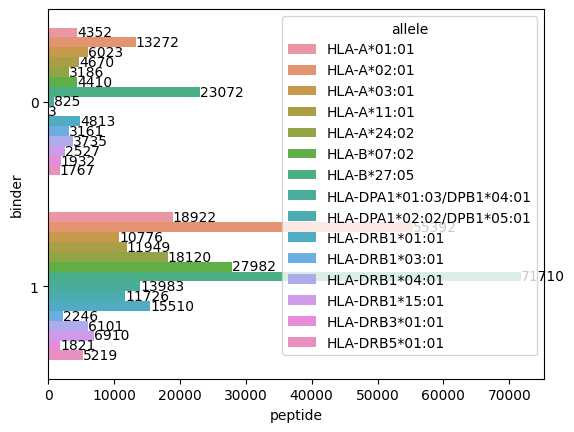

In [25]:
import seaborn as sns
ax = sns.barplot(data=df.groupby(['allele', 'binder'], as_index=False)['peptide'].count(), y='binder', x='peptide', hue='allele', orient='horizontal')
for container in ax.containers:
    ax.bar_label(container)

#  Save per allele DF

In [26]:
import mhcnames

TARGET_PATH_TO_FILES = DATA_PATH + EXPERIMENT_NAME + '/' 

for allele_name in ALLELES:
    total_df = per_allele_df[allele_name]
    compact_name = mhcnames.compact_allele_name(allele_name)
    # allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    total_df.to_csv("{}data_{}.csv".format(TARGET_PATH_TO_FILES,compact_name),sep=";", index=False)

In [27]:
total_df

,peptide,Parent Species,qualitative_measurement,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_id,peptide_start,peptide_end,measurement_type,binder,length
299359,KVTVAFNQF,Cryptomeria japonica,Positive,500.0,<,HLA-DPA1*02:02/DPB1*05:01,II,3D structure,x-ray crystallography,http://www.uniprot.org/uniprot/P18632,235.0,243.0,qualitative,1,9
299375,EVTVAFNQF,NaN,Positive-Low,5000.0,<,HLA-DPA1*02:02/DPB1*05:01,II,qualitative binding,purified MHC,NaN,NaN,NaN,qualitative,0,9
299376,KVYVAFNQF,NaN,Positive,500.0,<,HLA-DPA1*02:02/DPB1*05:01,II,qualitative binding,purified MHC,NaN,NaN,NaN,qualitative,1,9
299377,KVTVAFQQF,NaN,Positive-Low,5000.0,<,HLA-DPA1*02:02/DPB1*05:01,II,qualitative binding,purified MHC,NaN,NaN,NaN,qualitative,0,9
299378,KVTVAFNEF,NaN,Positive,500.0,<,HLA-DPA1*02:02/DPB1*05:01,II,qualitative binding,purified MHC,NaN,NaN,NaN,qualitative,1,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1327903,WELRTLISQSKDTASK,Homo sapiens,Positive,500.0,<,HLA-DPA1*02:02/DPB1*05:01,II,ligand presentation,cellular MHC/mass spectrometry,http://www.uniprot.org/uniprot/F5H4R1,1275.0,1290.0,qualitative,1,16
1327904,ELRTLISQSKDTASK,Homo sapiens,Positive,500.0,<,HLA-DPA1*02:02/DPB1*05:01,II,ligand presentation,cellular MHC/mass spectrometry,http://www.uniprot.org/uniprot/F5H4R1,1276.0,1290.0,qualitative,1,15
1327905,ELRTLISQSKDTAS,Homo sapiens,Positive,500.0,<,HLA-DPA1*02:02/DPB1*05:01,II,ligand presentation,cellular MHC/mass spectrometry,http://www.uniprot.org/uniprot/F5H4R1,1276.0,1289.0,qualitative,1,14
1327906,EIEVLRTTSKING,Homo sapiens,Positive,500.0,<,HLA-DPA1*02:02/DPB1*05:01,II,ligand presentation,cellular MHC/mass spectrometry,http://www.uniprot.org/uniprot/Q9Y6W3,208.0,220.0,qualitative,1,13


In [33]:
total_df['binder'].value_counts()

1    13983
0      825
Name: binder, dtype: int64